# Train / Test

We'll start by creating some data set that we want to build a model for (in this case a polynomial regression):

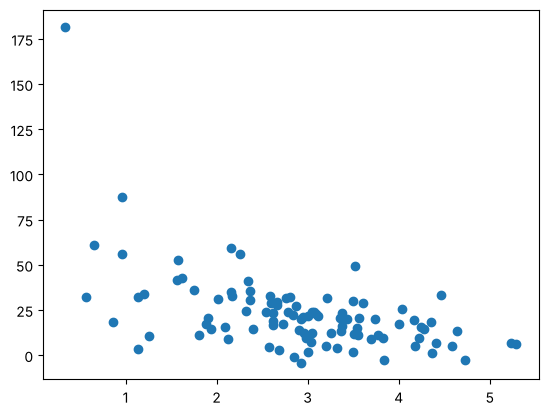

In [1]:
%matplotlib inline
import numpy as np
from pylab import *

np.random.seed(2)

pageSpeeds = np.random.normal(3.0, 1.0, 100)
purchaseAmount = np.random.normal(50.0, 30.0, 100) / pageSpeeds


scatter(pageSpeeds, purchaseAmount)

Now we'll split the data in two - 80% of it will be used for "training" our model, and the other 20% for testing it. This way we can avoid overfitting.

In [2]:
trainX = pageSpeeds[:80]
testX = pageSpeeds[80:]

trainY = purchaseAmount[:80]
testY = purchaseAmount[80:]


Here's our training dataset:

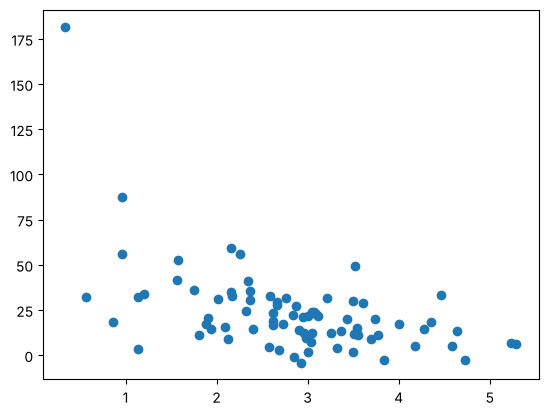

In [3]:
scatter(trainX, trainY)

And our test dataset:

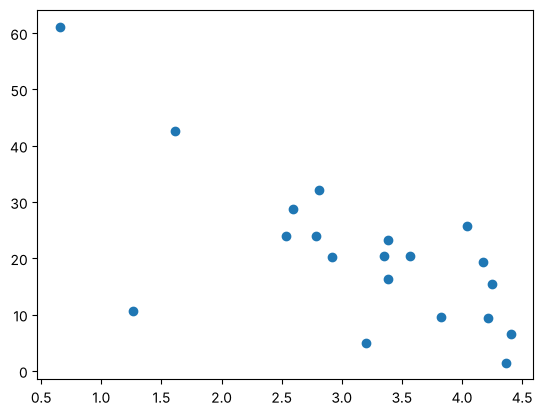

In [4]:
scatter(testX, testY)

Now we'll try to fit an 8th-degree polynomial to this data

In [5]:
x = np.array(trainX)
y = np.array(trainY)

p4 = np.poly1d(np.polyfit(x, y, 8))

Let's plot our polynomial against the training data:

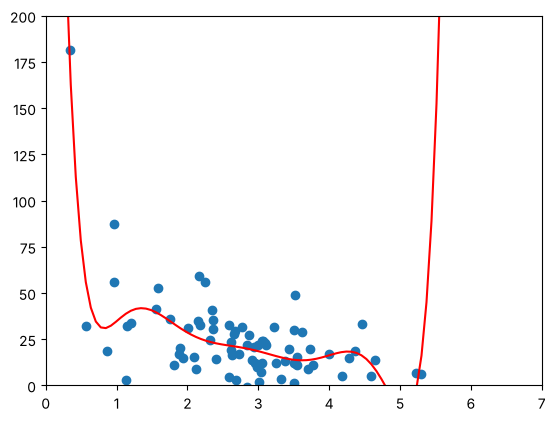

In [6]:
import matplotlib.pyplot as plt

xp = np.linspace(0, 7, 100)
axes = plt.axes()
axes.set_xlim([0,7])
axes.set_ylim([0, 200])
plt.scatter(x, y)
plt.plot(xp, p4(xp), c='r')
plt.show()


And against our test data:

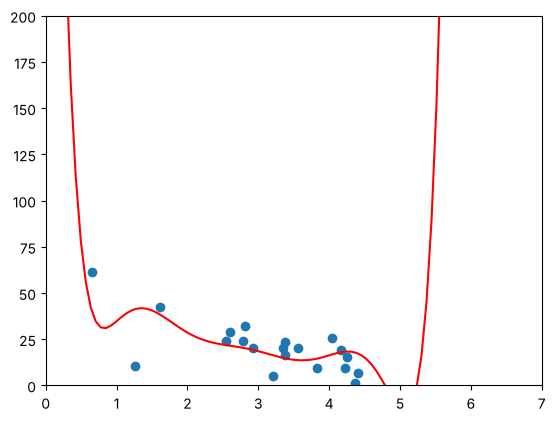

In [7]:
testx = np.array(testX)
testy = np.array(testY)

axes = plt.axes()
axes.set_xlim([0,7])
axes.set_ylim([0, 200])
plt.scatter(testx, testy)
plt.plot(xp, p4(xp), c='r')
plt.show()

From the plot can you predict if we created a good model?

Try calculating the R-squared on both sets (train and test) what can you conclude?

To fit the test data :

In [8]:
from sklearn.metrics import r2_score

r2 = r2_score(testy, p4(testx))

print(r2)


0.3001816861142774


To fit the training data :

In [9]:
from sklearn.metrics import r2_score

r2 = r2_score(np.array(trainY), p4(np.array(trainX)))

print(r2)

0.6427069514692536


## Activity 

<ol>
    <li>Try measuring the error on the test data using different degree polynomial fits. What degree works best? </li>
    <li>Scikit-learn has a built-in train_test_split function. Use it instead </li>
    <li>Try different data percentage splits, what can you conclude ?  </li>
    <li>is there a better solution? What is it? try it</li>
</ol>

In [10]:
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# 1) erreur sur les données de test pour différents degrés
resultats = []
for d in range(1, 13):
    p = np.poly1d(np.polyfit(trainX, trainY, d))
    r2_train = r2_score(trainY, p(trainX))
    r2_test = r2_score(testY, p(testX))
    mse_test = mean_squared_error(testY, p(testX))
    resultats.append((d, r2_train, r2_test, mse_test))

import pandas as pd
tab = pd.DataFrame(resultats, columns=['Degré', 'R² train', 'R² test', 'MSE test'])
print(tab.round(4).to_string(index=False))
print()
print("Meilleur degré (MSE test le plus faible) :", int(tab.loc[tab['MSE test'].idxmin(), 'Degré']))

 Degré  R² train  R² test  MSE test
     1    0.2647   0.4225  103.5442
     2    0.3616   0.2935  126.6820
     3    0.4296   0.2727  130.4045
     4    0.4831   0.3936  108.7288
     5    0.5545   0.5041   88.9248
     6    0.6025   0.6050   70.8253
     7    0.6170   0.5461   81.3808
     8    0.6427   0.3002  125.4845
     9    0.6634   0.2162  140.5513
    10    0.6819   0.2249  138.9919
    11    0.6875   0.2682  131.2231
    12    0.6919   0.0595  168.6363

Meilleur degré (MSE test le plus faible) : 6


Avec le découpage du début (80 premiers points pour l'entraînement et les 20 derniers pour le test), le meilleur degré sur le test est le **degré 6** (R² test = 0.605, MSE = 70.8). Au-delà, le R² d'entraînement continue d'augmenter (0.64 pour le degré 8, 0.69 pour le degré 12) alors que celui du test chute (0.30 pour le degré 8 et 0.06 pour le degré 12) : c'est du surapprentissage. Le degré 8 de l'énoncé est donc un mauvais choix, on le voyait déjà sur le graphique du test avec R² test = 0.30 contre 0.64 sur le train.

Avec `train_test_split` (découpage aléatoire, `random_state=42`) le meilleur degré devient le **degré 3** (R² test = 0.285, MSE = 992), et au-delà du degré 6 les résultats s'effondrent (R² test de -0.03 pour 7 jusqu'à -4.27 pour 10). On voit que le meilleur degré dépend du découpage choisi, et que le découpage sans mélange (premiers 80 points) n'est pas forcément représentatif.

In [11]:
# 2) avec train_test_split de scikit-learn (le découpage est aléatoire cette fois)
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(pageSpeeds, purchaseAmount, test_size=0.2, random_state=42)

resultats = []
for d in range(1, 11):
    p = np.poly1d(np.polyfit(X_tr, y_tr, d))
    resultats.append((d, r2_score(y_tr, p(X_tr)), r2_score(y_te, p(X_te)), mean_squared_error(y_te, p(X_te))))
tab2 = pd.DataFrame(resultats, columns=['Degré', 'R² train', 'R² test', 'MSE test'])
print(tab2.round(4).to_string(index=False))
print()
print("Meilleur degré :", int(tab2.loc[tab2['MSE test'].idxmin(), 'Degré']))

 Degré  R² train  R² test  MSE test
     1    0.2891   0.1829 1133.6363
     2    0.3001   0.2453 1047.0387
     3    0.3035   0.2849  992.1512
     4    0.3036   0.2755 1005.2010
     5    0.3057   0.1979 1112.8930
     6    0.3073   0.2847  992.3848
     7    0.3155  -0.0272 1425.1361
     8    0.3295  -1.0313 2818.2935
     9    0.3402  -3.1586 5769.6776
    10    0.3410  -4.2665 7306.8230

Meilleur degré : 3


In [12]:
# 3) différents pourcentages de test, on répète avec plusieurs découpages aléatoires et on fait la moyenne
d = 3
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    scores_te = []
    scores_tr = []
    for seed in range(30):
        a, b, c, e = train_test_split(pageSpeeds, purchaseAmount, test_size=t, random_state=seed)
        p = np.poly1d(np.polyfit(a, c, d))
        scores_tr.append(r2_score(c, p(a)))
        scores_te.append(r2_score(e, p(b)))
    print("test_size =", t, "-> R² train moyen =", round(np.mean(scores_tr), 3),
          " R² test moyen =", round(np.mean(scores_te), 3), " écart-type test =", round(np.std(scores_te), 3))

test_size = 0.1 -> R² train moyen = 0.438  R² test moyen = -0.414  écart-type test = 0.715
test_size = 0.2 -> R² train moyen = 0.422  R² test moyen = -0.271  écart-type test = 0.69
test_size = 0.3 -> R² train moyen = 0.42  R² test moyen = -0.15  écart-type test = 0.811
test_size = 0.4 -> R² train moyen = 0.441  R² test moyen = -0.189  écart-type test = 0.624
test_size = 0.5 -> R² train moyen = 0.426  R² test moyen = -0.016  écart-type test = 0.517
test_size = 0.6 -> R² train moyen = 0.438  R² test moyen = -0.037  écart-type test = 0.591


Pour le degré 3, j'ai répété le découpage 30 fois pour chaque pourcentage. Le R² d'entraînement est stable (environ 0.42-0.44), mais le R² moyen sur le test est très variable et même négatif pour des petits jeux de test (-0.41 pour 10%, -0.27 pour 20%, -0.15 pour 30%) et proche de 0 pour 50% et 60%. L'écart-type du R² test est grand (0.5 à 0.8) : selon les points qui tombent dans le test (surtout les valeurs extrêmes quand pageSpeeds est proche de 0), le résultat change beaucoup.

Conclusion : avec seulement 100 points, un seul découpage donne une estimation peu fiable. Un petit jeu de test donne des scores instables, mais un grand jeu de test laisse trop peu de données pour apprendre. Un compromis classique (70/30 ou 80/20) est raisonnable, mais il vaut mieux utiliser la validation croisée.

In [13]:
# 4) une meilleure solution : choisir le degré par validation croisée (k-fold) plutôt que sur un seul découpage
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

Xall = pageSpeeds.reshape(-1, 1)
kf = KFold(n_splits=5, shuffle=True, random_state=0)

cv_res = []
for d in range(1, 11):
    modele = make_pipeline(PolynomialFeatures(d), LinearRegression())
    s = cross_val_score(modele, Xall, purchaseAmount, cv=kf, scoring='neg_mean_squared_error')
    cv_res.append((d, -s.mean()))
cv_tab = pd.DataFrame(cv_res, columns=['Degré', 'MSE (CV 5 plis)'])
print(cv_tab.round(2).to_string(index=False))
print("Meilleur degré par validation croisée :", int(cv_tab.loc[cv_tab['MSE (CV 5 plis)'].idxmin(), 'Degré']))

 Degré  MSE (CV 5 plis)
     1           401.40
     2           398.18
     3           420.54
     4           478.86
     5           456.14
     6           437.28
     7           460.73
     8           442.39
     9           428.97
    10           426.00
Meilleur degré par validation croisée : 2


In [14]:
# On sait aussi que les données ont été générées avec purchaseAmount = bruit / pageSpeeds
# donc on peut essayer un modèle linéaire sur la variable 1/x
inv = (1 / pageSpeeds).reshape(-1, 1)
s_inv = cross_val_score(LinearRegression(), inv, purchaseAmount, cv=kf, scoring='neg_mean_squared_error')
print("MSE (CV) avec la variable 1/x :", round(-s_inv.mean(), 2))

# régularisation Ridge sur un polynôme de degré 8
rid = make_pipeline(PolynomialFeatures(8), StandardScaler(), Ridge(alpha=10))
s_ridge = cross_val_score(rid, Xall, purchaseAmount, cv=kf, scoring='neg_mean_squared_error')
print("MSE (CV) polynôme degré 8 + Ridge :", round(-s_ridge.mean(), 2))

MSE (CV) avec la variable 1/x : 300.71
MSE (CV) polynôme degré 8 + Ridge : 396.37


**Une meilleure solution : la validation croisée.** Avec 5 plis, on évalue chaque degré sur tout le jeu de données (chaque point est utilisé une fois en test). Le MSE minimum est obtenu pour le degré 2 (398), très proche du degré 1 (401), et il augmente ensuite (479 pour le degré 4), ce qui confirme qu'un degré élevé n'est pas utile ici.

On peut faire encore mieux en utilisant ce qu'on sait des données : elles ont été générées avec `purchaseAmount = bruit / pageSpeeds`. Une régression linéaire sur la variable `1/x` donne un MSE de 300.7 en validation croisée, nettement meilleur que n'importe quel polynôme (≥ 398). Enfin, un polynôme de degré 8 avec régularisation Ridge donne 396 au lieu de 442 sans régularisation, donc la régularisation limite le surapprentissage mais reste moins bonne que le bon choix de variable.